# 03 — Definições e sensibilidade

**Pergunta:** quanto a taxa de retorno em 7 dias muda se uma definição mudar?

- Todas as definições vêm de `etl/definicoes.py`, o mesmo código da carga. Os testes em
  `tests/test_definicoes.py` fixam o comportamento de cada regra.
- Método: parte do padrão e muda **um parâmetro por vez**. IC 95% de Wilson.

In [1]:
from estilo import AZUL, BRUTA, CRITICO, TINTA_2, TINTA_MUDA, VOLUME, aplicar, nota  # põe etl/ no path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from definicoes import VERSAO_DEFINICOES, Definicoes, construir, elegiveis
from estatistica import wilson

aplicar()
pd.set_option("display.width", 160)


def medir(d: Definicoes) -> tuple[pd.DataFrame, pd.DataFrame]:
    u = construir(duckdb.connect(), BRUTA, d, volume_diario=VOLUME)
    return u, elegiveis(u, d)

## 1. Definições padrão

In [2]:
BDR = {
    "chave_usuario": "BDR-001", "max_uas_por_ip": "BDR-001", "unidade_atividade": "BDR-002",
    "gap_sessao_min": "BDR-002", "aquecimento_semanas": "BDR-003", "regra_retorno": "BDR-004",
    "janela_retorno_dias": "BDR-004", "fuso": "BDR-005", "excluir_janela_com_lacuna": "BDR-006",
    "limiar_lacuna": "BDR-006", "excluir_sem_conteudo": "BDR-008",
}
padrao = Definicoes()
print("versão das definições:", VERSAO_DEFINICOES)
pd.DataFrame([{"parâmetro": k, "valor": v, "registro": BDR[k]} for k, v in padrao.como_dict().items()])

versão das definições: 2026-11-11.1


,parâmetro,valor,registro
0,chave_usuario,ip,BDR-001
1,max_uas_por_ip,None,BDR-001
2,unidade_atividade,turno,BDR-002
3,gap_sessao_min,30,BDR-002
4,aquecimento_semanas,0,BDR-003
5,regra_retorno,nova_sessao,BDR-004
6,janela_retorno_dias,7,BDR-004
7,fuso,America/Sao_Paulo,BDR-005
8,excluir_janela_com_lacuna,True,BDR-006
9,limiar_lacuna,0.15,BDR-006


Em linguagem de negócio:
- **Usuário** = um IP (com hash).
- **Sessão** = sequência de respostas do assistente com menos de 30 minutos entre elas. Continuar uma
  conversa antiga também é atividade.
- **Primeira experiência** = a primeira sessão do usuário na base.
- **Voltou em 7 dias** = teve uma nova sessão em até 7 × 24 h depois do início da primeira.
- **Denominador** = usuários com 7 dias observáveis e sem falha de coleta na janela.

## 2. Do total de usuários ao denominador

In [3]:
u, e = medir(padrao)
funil = pd.DataFrame(
    {
        "etapa": ["usuários (IPs com uso)", "com 7 dias observáveis", "sem falha de coleta na janela", "voltaram em 7 dias"],
        "pessoas": [len(u), int(u.observavel_7d.sum()), len(e), int(e.voltou_7d.sum())],
    }
)
lo, hi = wilson(int(e.voltou_7d.sum()), len(e))
print(f"retorno em 7 dias: {e.voltou_7d.mean():.1%} (IC 95% {lo:.1%} a {hi:.1%})")
funil

retorno em 7 dias: 28.6% (IC 95% 26.8% a 30.5%)


,etapa,pessoas
0,usuários (IPs com uso),2354
1,com 7 dias observáveis,2306
2,sem falha de coleta na janela,2219
3,voltaram em 7 dias,635


## 3. Sensibilidade: um parâmetro por vez

In [4]:
VARIANTES = {
    "Padrão": {},
    "Usuário = IP + user-agent": {"chave_usuario": "ip_ua"},
    "Usuário = IP + accept-language": {"chave_usuario": "ip_lang"},
    "Exclui IP com > 10 user-agents": {"max_uas_por_ip": 10},
    "Atividade = só início de conversa": {"unidade_atividade": "conversa"},
    "Sessão com gap de 15 min": {"gap_sessao_min": 15},
    "Sessão com gap de 60 min": {"gap_sessao_min": 60},
    "Aquecimento de 2 semanas": {"aquecimento_semanas": 2},
    "Aquecimento de 4 semanas": {"aquecimento_semanas": 4},
    "Retorno = atividade > 1h após o início": {"regra_retorno": "apos_1h"},
    "Retorno = atividade em outro dia": {"regra_retorno": "dia_seguinte"},
    "Mantém janela com falha de coleta": {"excluir_janela_com_lacuna": False},
    "Inclui conversa sem conteúdo": {"excluir_sem_conteudo": False},
    "Referência do incidente (IP+UA, conversa, > 1h)": {
        "chave_usuario": "ip_ua", "unidade_atividade": "conversa", "regra_retorno": "apos_1h"},
}
linhas = []
for nome, kw in VARIANTES.items():
    _, el = medir(Definicoes(**kw))
    n, k = len(el), int(el.voltou_7d.sum())
    lo, hi = wilson(k, n)
    linhas.append({"variante": nome, "denominador": n, "voltaram": k, "taxa": k / n, "ic_inf": lo, "ic_sup": hi})
sens = pd.DataFrame(linhas)
sens["delta_pp"] = (sens.taxa - sens.taxa.iloc[0]) * 100
sens.to_csv("../data/work/sensibilidade.csv", index=False)
(sens.assign(**{c: (sens[c] * 100).round(1) for c in ["taxa", "ic_inf", "ic_sup"]}).round({"delta_pp": 1}))

,variante,denominador,voltaram,taxa,ic_inf,ic_sup,delta_pp
0,Padrão,2219,635,28.6,26.8,30.5,0.0
1,Usuário = IP + user-agent,2685,827,30.8,29.1,32.6,2.2
2,Usuário = IP + accept-language,2360,676,28.6,26.9,30.5,0.0
3,Exclui IP com > 10 user-agents,2216,632,28.5,26.7,30.4,-0.1
4,Atividade = só início de conversa,2219,539,24.3,22.6,26.1,-4.3
5,Sessão com gap de 15 min,2219,754,34.0,32.0,36.0,5.4
6,Sessão com gap de 60 min,2219,558,25.1,23.4,27.0,-3.5
7,Aquecimento de 2 semanas,2157,609,28.2,26.4,30.2,-0.4
8,Aquecimento de 4 semanas,2026,564,27.8,25.9,29.8,-0.8
9,Retorno = atividade > 1h após o início,2219,600,27.0,25.2,28.9,-1.6


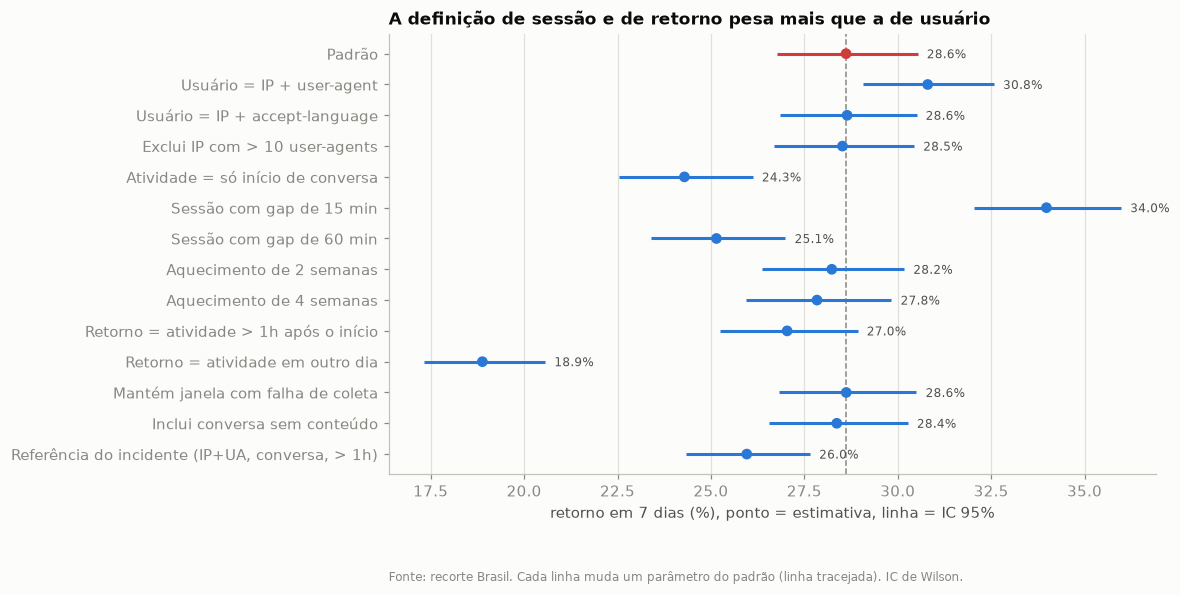

In [5]:
s = sens.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 5.2))
base = sens.taxa.iloc[0] * 100
ax.axvline(base, color=TINTA_MUDA, lw=1, ls="--")
cores = [AZUL if v != "Padrão" else CRITICO for v in s.variante]
ax.hlines(s.index, s.ic_inf * 100, s.ic_sup * 100, color=cores, lw=2)
ax.scatter(s.taxa * 100, s.index, color=cores, s=36, zorder=3)
for i, r in s.iterrows():
    ax.annotate(f"{r.taxa * 100:.1f}%", (r.ic_sup * 100, i), xytext=(6, -3), textcoords="offset points",
                fontsize=8, color=TINTA_2)
ax.set_yticks(s.index, s.variante)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("retorno em 7 dias (%), ponto = estimativa, linha = IC 95%")
ax.set_title("A definição de sessão e de retorno pesa mais que a de usuário")
nota(ax, "Fonte: recorte Brasil. Cada linha muda um parâmetro do padrão (linha tracejada). IC de Wilson.")
plt.show()

**Achados:**
- A taxa padrão é **28,6% (IC 26,8%–30,5%)**, com 2.219 pessoas no denominador.
- **Gap de sessão** e **regra de retorno** são as escolhas que mais pesam: de 18,9% ("outro dia") a 34,0%
  (gap de 15 min). Por isso o dashboard mostra a definição ao lado do número.
- **Atividade por conversa** em vez de por resposta tira 4,3 p.p.: ignora quem continua uma conversa aberta.
- **Chave de usuário:** IP + user-agent dá +2,2 p.p. Ela separa IPs compartilhados em pessoas, mas também
  transforma uma atualização de navegador em "usuário novo" (o mecanismo do incidente, `docs/INCIDENTE.md`).
- **Aquecimento, falha de coleta e conversa vazia** mudam menos de 1 p.p. A base começa no lançamento do
  serviço (09/04/2023), então quase não há usuário antigo contado como novo.

## 4. Coorte semanal × mensal: o tamanho da amostra manda

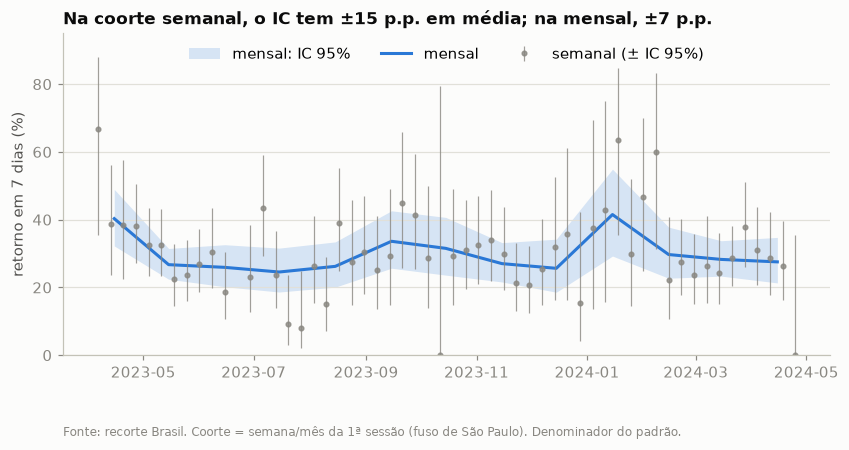

meia-largura média do IC: semanal ±15.3 p.p.; mensal ±7.3 p.p.; mediana n semanal = 39


,coorte_mes,n,k,ic_inf,ic_sup,taxa
0,2023-04-01,129,52,32.2,48.9,40.3
1,2023-05-01,363,97,22.4,31.5,26.7
2,2023-06-01,189,49,20.2,32.6,25.9
3,2023-07-01,167,41,18.6,31.6,24.6
4,2023-08-01,164,43,20.1,33.4,26.2
5,2023-09-01,116,39,25.7,42.6,33.6
6,2023-10-01,111,35,23.6,40.7,31.5
7,2023-11-01,222,60,21.6,33.2,27.0
8,2023-12-01,117,30,18.6,34.2,25.6
9,2024-01-01,53,22,29.3,54.9,41.5


In [6]:
def por_coorte(df: pd.DataFrame, col: str) -> pd.DataFrame:
    g = df.groupby(col).agg(n=("voltou_7d", "size"), k=("voltou_7d", "sum")).reset_index()
    g[["ic_inf", "ic_sup"]] = g.apply(lambda r: pd.Series(wilson(int(r.k), int(r.n))), axis=1)
    g["taxa"] = g.k / g.n
    return g


semana, mes = por_coorte(e, "coorte_semana"), por_coorte(e, "coorte_mes")
semanas_lacuna = set(u[u.janela_com_lacuna].coorte_semana)
fig, ax = plt.subplots(figsize=(9, 3.8))
mes_meio = pd.to_datetime(mes.coorte_mes) + pd.Timedelta(days=14)
ax.fill_between(mes_meio, mes.ic_inf * 100, mes.ic_sup * 100, color=AZUL, alpha=0.18, lw=0, label="mensal: IC 95%")
ax.plot(mes_meio, mes.taxa * 100, color=AZUL, label="mensal")
sem_x = pd.to_datetime(semana.coorte_semana) + pd.Timedelta(days=3)
ax.errorbar(sem_x, semana.taxa * 100, yerr=[((semana.taxa - semana.ic_inf) * 100).clip(lower=0), ((semana.ic_sup - semana.taxa) * 100).clip(lower=0)],
            fmt="o", ms=3, color=TINTA_MUDA, ecolor=TINTA_MUDA, elinewidth=0.8, alpha=0.8, label="semanal (± IC 95%)")
ax.set_ylabel("retorno em 7 dias (%)")
meia_sem = ((semana.ic_sup - semana.ic_inf) / 2).mean() * 100
meia_mes = ((mes.ic_sup - mes.ic_inf) / 2).mean() * 100
ax.set_ylim(0, 95)
ax.legend(loc="upper center", ncols=3)
ax.set_title(f"Na coorte semanal, o IC tem ±{meia_sem:.0f} p.p. em média; na mensal, ±{meia_mes:.0f} p.p.")
nota(ax, "Fonte: recorte Brasil. Coorte = semana/mês da 1ª sessão (fuso de São Paulo). Denominador do padrão.")
plt.show()
print(f"meia-largura média do IC: semanal ±{meia_sem:.1f} p.p.; mensal ±{meia_mes:.1f} p.p.; "
      f"mediana n semanal = {semana.n.median():.0f}")
mes.assign(taxa=lambda x: (x.taxa * 100).round(1), ic_inf=lambda x: (x.ic_inf * 100).round(1),
           ic_sup=lambda x: (x.ic_sup * 100).round(1))

**Achado:** com ~39 pessoas por semana, o IC semanal (±15 p.p.) é largo demais para comparar uma semana com outra.
A coorte **mensal** mantém o IC perto de ±7 p.p.

**Decisão para o dashboard:**
- A visão principal é **mensal**.
- A semanal aparece como detalhe, com o IC e o aviso "amostra pequena".
- Regra de amostra mínima: se o IC passar de ±10 p.p. (cerca de 80 pessoas), o número aparece esmaecido.

Dois meses fogem do padrão: abril/2023 (40%, lançamento, primeiros adeptos) e janeiro/2024 (42%, férias,
poucos novos). O notebook 05 testa se a mudança é de perfil ou de taxa.

## 5. Decisões registradas
BDR-001 a BDR-006 e BDR-008 em `docs/bdr/`, com os números desta análise.